In [8]:
import numpy as np 
import matplotlib.pyplot as plt

In [9]:
P1 = np.array([[0.3,   0.4,    0.3   ],
               [0.05,  0.8875, 0.0625],
               [0.3,   0.5,    0.2   ]])

P2 = np.array([[0.5,   0.2,    0.3   ],
               [0.025, 0.9125, 0.0625],
               [0.3,   0.5,    0.2   ]])

transition_probs1 = [
    (0, 0, 0.3),
    (0, 1, 0.4),
    (0, 2, 0.3),
    (1, 0, 0.05),
    (1, 1, 0.8875),
    (1, 2, 0.0625),
    (2, 0, 0.3),
    (2, 1, 0.5),
    (2, 2, 0.2)]

transition_probs2 = [
    (0, 0, 0.5),
    (0, 1, 0.2),
    (0, 2, 0.3),
    (1, 0, 0.025),
    (1, 1, 0.9125),
    (1, 2, 0.0625),
    (2, 0, 0.3),
    (2, 1, 0.5),
    (2, 2, 0.2)]



In [10]:
class Node:
    def __init__(self, index):
        self.index = index
        self.neighbors = []

    def add_neighbor(self, other_node, transition_prob):
        self.neighbors.append((other_node, transition_prob))

    def draw_next(self):
        next_node = [next for next, prob in self.neighbors] # What node? [Node0, Node1, Node2]
        probs = [prob for next, prob in self.neighbors]    # What corresponding probability? [p0, p1, p2]
        return np.random.choice(next_node, p=probs)         # Choose node with given probabilites

nodes1 = [Node(i) for i in range(3)]
for i, j, p in transition_probs1:
    nodes1[i].add_neighbor(nodes1[j], p)

nodes2 = [Node(i) for i in range(3)]
for i, j, p in transition_probs2:
    nodes2[i].add_neighbor(nodes2[j], p)

In [11]:
class System():
    def __init__(self, nodes, p0, start_index=0):
        self.nodes = nodes
        self.n_states = len(nodes)
        self.current_node = nodes[start_index]
        self.trajectory = [start_index]

        self.P = np.zeros((self.n_states, self.n_states)) # create 3 x 3 matrix
        for node in nodes:                              # There are three nodes
            for other_node, prob in node.neighbors:     # Node neighbors is a list of all elements in a row, meaning other_node=[0,1,2]          
                self.P[node.index, other_node.index] = prob
        # This is deterministic
        self.p = np.array(p0)                           # What state do we start in? can be a probability i think
        self.history = [self.p.copy()]                  # record what states we enter
        # This is stochastic
        self.current_node = nodes[start_index]

        self.visits = np.zeros(self.n_states)           # Make an array with entries equal to the number of states
        self.visits[start_index] += 1                   # Make sure to record starting state

    def step(self):
        self.p = self.p @ self.P                    # Do the step as Eq 19 describes in exercises 
        self.history.append(self.p.copy())          # again, we record steps

    def propagate(self, n):                         # This method just steps n times
        for _ in range(n):
            self.step()
        return self.p

    def next_state(self):
        self.current_node = self.current_node.draw_next()
        self.trajectory.append(self.current_node.index)
        self.visits[self.current_node.index] += 1       # Count the visit
        return self.current_node.index

In [12]:
N = 1_000_000
system1 = System(nodes1, [1, 0, 0], start_index=0)
system2 = System(nodes2, [1, 0, 0], start_index=0)
for _ in range(N - 1):
    system1.next_state()
    system2.next_state()

pi_hat1 = system1.visits / N
pi_hat2 = system2.visits / N
print(system1.visits, system1.visits.sum())
print(pi_hat1)
print("###")
print(system2.visits, system1.visits.sum())
print(pi_hat2)

[100799. 799181. 100020.] 1000000.0
[0.100799 0.799181 0.10002 ]
###
[100083. 800008.  99909.] 1000000.0
[0.100083 0.800008 0.099909]


#### Law of large numbers

#### Probability distribution from an ensemble, give X_n, which depend on n(step), it will approach [0.1,0.8,0.1] as n grows meaning it show how the distribution evolves with steps
#### Time average from a long chain, this is recording when each state happens, and then dividing by the total number of steps, this will estimate the long run odds

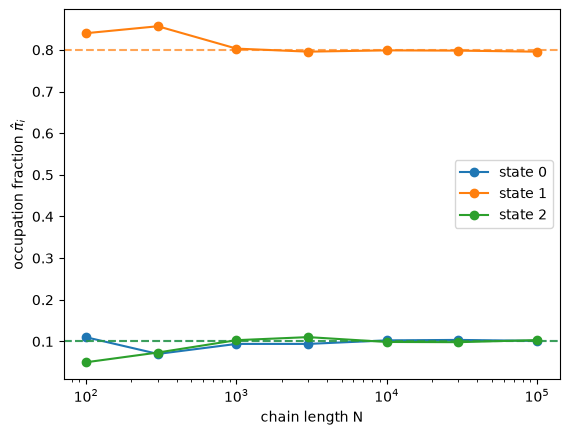

In [13]:
lengths = [100, 300, 1000, 3000, 10000, 30000, 100000]

pis = []
for N in lengths:
    system = System(nodes1, [1, 0, 0], start_index=0)    # use nodes2 for P(2)
    for _ in range(N - 1):
        system.next_state()
    pis.append(system.visits / N)
pis = np.array(pis)

colors = ["tab:blue", "tab:orange", "tab:green"]
for i in range(3):
    plt.plot(lengths, pis[:, i], "o-", color=colors[i], label=f"state {i}")
    plt.axhline([0.1, 0.8, 0.1][i], color=colors[i], linestyle="--", alpha=0.7)
plt.xscale("log")
plt.xlabel("chain length N")
plt.ylabel(r"occupation fraction $\hat{\pi}_i$")
plt.legend()
plt.show()